In [34]:
from pathlib import Path
import pandas as pd

In [35]:

project_dir = Path(r"E:\Projects\KIO-ML-Customer-Intent-Routing")

data_path = project_dir / "data" / "dataset.csv"

print("Dataset exists:", data_path.exists())

Dataset exists: True


In [36]:
data_path = project_dir / "data" / "dataset.csv"
df = pd.read_csv(data_path, encoding="utf-8-sig")

In [37]:
train_df = df[df["split"] == "train"]

X_train = train_df["message"]
y_train = train_df["label"]

print("Project directory:", project_dir)
print("Training messages:", len(X_train))
print("\nClass Distribution:")
print(y_train.value_counts().sort_index())

Project directory: E:\Projects\KIO-ML-Customer-Intent-Routing
Training messages: 40

Class Distribution:
label
0    20
1    20
Name: count, dtype: int64


In [38]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF Vectorizer
vectorizer = TfidfVectorizer(ngram_range=(1, 2))

# Learn vocabulary and transform training messages
X_train_tfidf = vectorizer.fit_transform(X_train)

print("TF-IDF Shape:", X_train_tfidf.shape)

print("Vocabulary Size:", len(vectorizer.get_feature_names_out()))


TF-IDF Shape: (40, 675)
Vocabulary Size: 675


In [39]:
#Dimensionality Reduction

from sklearn.decomposition import TruncatedSVD

# Reduce 675 features to 2 dimensions
svd = TruncatedSVD(n_components=2, random_state=351)

X_train_2d = svd.fit_transform(X_train_tfidf)

print("Original Shape:", X_train_tfidf.shape)
print("Reduced Shape:", X_train_2d.shape)

print("Explained Variance:", svd.explained_variance_ratio_.sum())


Original Shape: (40, 675)
Reduced Shape: (40, 2)
Explained Variance: 0.051836864652194975


In [40]:
#Linear Support Vector Machine (SVM) Training
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

# Create a Linear SVM classifier
model = SVC(kernel="linear", C=1.0)

# Train
model.fit(X_train_2d, y_train)

# Predict training messages
y_train_pred = model.predict(X_train_2d)

# Evaluate
print("Training Accuracy:", accuracy_score(y_train, y_train_pred))

print("\nTraining Confusion Matrix:")
print(confusion_matrix(y_train, y_train_pred, labels=[0, 1]))

print("\nSupport Vectors:", model.n_support_)


Training Accuracy: 0.875

Training Confusion Matrix:
[[16  4]
 [ 1 19]]

Support Vectors: [17 17]


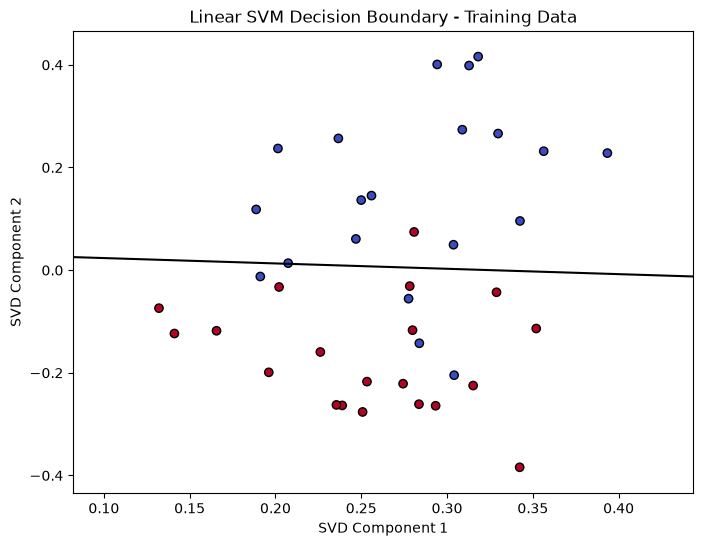

In [41]:
# Decision Boundary Visualization
import numpy as np
import matplotlib.pyplot as plt

x_min = X_train_2d[:, 0].min() - 0.05
x_max = X_train_2d[:, 0].max() + 0.05
y_min = X_train_2d[:, 1].min() - 0.05
y_max = X_train_2d[:, 1].max() + 0.05

# Create a 2D grid 
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

# Predict the decision scores
grid = np.c_[xx.ravel(), yy.ravel()]
scores = model.decision_function(grid).reshape(xx.shape)

# Plot decision boundary
plt.figure(figsize=(8, 6))
plt.contour(xx, yy, scores, levels=[0], colors="black")

# Plot training samples
plt.scatter(
    X_train_2d[:, 0],
    X_train_2d[:, 1],
    c=y_train,
    cmap="coolwarm",
    edgecolors="black"
)

plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("Linear SVM Decision Boundary - Training Data")

plt.savefig(project_dir / "results" / "boundary.png", dpi=300, bbox_inches="tight")
plt.show()


In [42]:
#Model Evaluation

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

test_df = df[df["split"] == "test"]

X_test = test_df["message"]
y_test = test_df["label"]

# Transform using the trained TF-IDF and SVD
X_test_tfidf = vectorizer.transform(X_test)
X_test_2d = svd.transform(X_test_tfidf)

# Predict test labels
y_test_pred = model.predict(X_test_2d)

# Evaluate predictions 
print("Test Messages:", len(X_test))
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["Support", "Sales"],
    zero_division=0
))


Test Messages: 20
Test Accuracy: 0.9

Confusion Matrix:
[[9 1]
 [1 9]]

Classification Report:
              precision    recall  f1-score   support

     Support       0.90      0.90      0.90        10
       Sales       0.90      0.90      0.90        10

    accuracy                           0.90        20
   macro avg       0.90      0.90      0.90        20
weighted avg       0.90      0.90      0.90        20



In [43]:
#Save Predictions & Error Analysis

# Create evaluation results
ml_results = pd.DataFrame({
    "id": test_df["id"].to_numpy(),
    "y_true": y_test.to_numpy(),
    "y_pred": y_test_pred,
    "valid": True,
    "error": ""
})

# Save predictions 
output_path = project_dir / "results" / "ml_results.csv"
ml_results.to_csv(output_path, index=False)

print("Results saved:", output_path)

# Find misclassified messages
wrong = ml_results[
    ml_results["y_true"] != ml_results["y_pred"]
]

print("\nMisclassified Messages:")
print(
    test_df.loc[
        test_df["id"].isin(wrong["id"]),
        ["id", "message", "label", "case_type"]
    ].to_string(index=False)
)

print("\nTotal Errors:", len(wrong))


Results saved: E:\Projects\KIO-ML-Customer-Intent-Routing\results\ml_results.csv

Misclassified Messages:
 id                                                                                   message  label       case_type
M24           What pages and features are included in your basic website development package?      1 straightforward
M25 Please cancel our ongoing website redesign project before the next development milestone.      0 straightforward

Total Errors: 2


In [44]:
#Create `predict_ml()` function so that we can use the model in the KIO

# Predict the intent of a new customer message
def predict_ml(message: str) -> int:
    if not isinstance(message, str) or not message.strip():
        raise ValueError("Message must be a non-empty string")

    message_tfidf = vectorizer.transform([message])
    message_2d = svd.transform(message_tfidf)

    prediction = model.predict(message_2d)[0]
    return int(prediction)


# Test with new messages
print(predict_ml("The website you built for us is not working."))
print(predict_ml("How much does it cost to build a new website?"))


0
1


In [45]:
#Integrate ML with KIO Router
import sys

src_path = str(project_dir / "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

# Import the existing KIO Router
from kio.router import route_message

# Test Support routing
route_message(
    "The website you built for us is not working.",
    predict_ml
)

# Test Sales routing
route_message(
    "How much does it cost to build a new website?",
    predict_ml
)


Support Agent
Sales Agent


1

In [46]:
#Save Trained Model

import joblib

# Save all trained components
model_path = project_dir / "models" / "traditional_ml.joblib"
model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump({
    "vectorizer": vectorizer,
    "svd": svd,
    "model": model
}, model_path)

print("Model saved:", model_path)


Model saved: E:\Projects\KIO-ML-Customer-Intent-Routing\models\traditional_ml.joblib


In [47]:
#Load & Verify Saved Model

# Load the saved model components
saved = joblib.load(model_path)

# Transform test messages using the loaded components
saved_tfidf = saved["vectorizer"].transform(X_test)
saved_2d = saved["svd"].transform(saved_tfidf)

# Predict using the loaded SVM
saved_predictions = saved["model"].predict(saved_2d)

# Compare original and loaded predictions
print("Predictions Match:", (saved_predictions == y_test_pred).all())
print("Loaded Model Accuracy:", accuracy_score(y_test, saved_predictions))


Predictions Match: True
Loaded Model Accuracy: 0.9


In [48]:
#Compare Traditional ML vs Decision Model

# Load both models' results
ml = pd.read_csv(project_dir / "results" / "ml_results.csv")
decision = pd.read_csv(project_dir / "results" / "decision_results.csv")

# Keep required columns and rename them
decision = decision[["id", "label", "predicted_flag"]]
decision.columns = ["id", "y_true", "decision_pred"]

ml = ml[["id", "y_true", "y_pred"]]
ml = ml.rename(columns={"y_pred": "ml_pred"})

# Compare predictions using the same message IDs
comparison = ml.merge(
    decision,
    on=["id", "y_true"],
    validate="one_to_one"
)

assert len(comparison) == 20, "Test messages do not match"

# Calculate both models' accuracy
print("Traditional ML Accuracy:",
      accuracy_score(comparison["y_true"], comparison["ml_pred"]))

print("Decision Model Accuracy:",
      accuracy_score(comparison["y_true"], comparison["decision_pred"]))

# Show incorrect predictions
comparison["ml_correct"] = comparison["ml_pred"] == comparison["y_true"]
comparison["decision_correct"] = comparison["decision_pred"] == comparison["y_true"]

print("\nComparison of Incorrect Predictions:")
print(
    comparison[
        ~comparison["ml_correct"] | ~comparison["decision_correct"]
    ].to_string(index=False)
)


Traditional ML Accuracy: 0.9
Decision Model Accuracy: 0.75

Comparison of Incorrect Predictions:
 id  y_true  ml_pred  decision_pred  ml_correct  decision_correct
M06       1        1              0        True             False
M09       1        1              0        True             False
M10       1        1              0        True             False
M14       1        1              0        True             False
M24       1        0              0       False             False
M25       0        1              0       False              True


In [49]:
#Final Error Analysis & Save Comparison

# Add message details to the comparison
comparison = comparison.merge(
    test_df[["id", "message", "case_type"]],
    on="id",
    validate="one_to_one"
)

errors = comparison[
    ~comparison["ml_correct"] | ~comparison["decision_correct"]
]

# Display errors with their original messages
print("Error Analysis:")
print(errors[
    ["id", "message", "case_type", "y_true",
     "ml_pred", "decision_pred"]
].to_string(index=False))

# Save the full comparison
comparison_path = project_dir / "results" / "comparison.csv"
comparison.to_csv(comparison_path, index=False)

print("\nComparison saved:", comparison_path)


Error Analysis:
 id                                                                                                     message       case_type  y_true  ml_pred  decision_pred
M06                       What features would you include if you built live chat into our new business website?      paraphrase       1        1              0
M09 Before we commission development, can you explain the live-chat functionality you'd add to our new website?      paraphrase       1        1              0
M10                        Can you build a WordPress website for a company launching its first online presence? straightforward       1        1              0
M14              I'd like to schedule a consultation about building a members-only website for our association. straightforward       1        1              0
M24                             What pages and features are included in your basic website development package? straightforward       1        0              0
M25                   Pl


## Final Conclusion & Recommendation

### Results

The Traditional ML (Linear SVM) achieved a Test Accuracy of 90% (18/20), compared with 75% (15/20) for the Zero-shot DeBERTa Decision Model.

Linear SVM achieved 90% Recall for both Support and Sales. DeBERTa achieved 100% Support Recall and 50% Sales Recall.

### Recommendation

Linear SVM is recommended for the current KIO experiment due to its higher Accuracy and more balanced classification performance.

### Limitations

The evaluation was conducted on only 20 synthetic test messages. The DeBERTa 75% result is exploratory because its candidate labels were modified after an earlier test evaluation.

Further independent evaluation is required before deployment.





### Results

حقق نموذج Traditional ML (Linear SVM) نسبة Test Accuracy بلغت 90% (18/20)، مقارنةً بنسبة 75% (15/20) لنموذج Zero-shot DeBERTa Decision Model.

حقق Linear SVM نسبة Recall بلغت 90% لكل من Support وSales، بينما حقق DeBERTa نسبة 100% لفئة Support و50% لفئة Sales.

### Recommendation

نوصي باستخدام Linear SVM في تجربة KIO الحالية، نظرًا لتحقيقه Accuracy أعلى وأداءً أكثر توازنًا بين التصنيفين.

### Limitations

اعتمد التقييم على 20 Synthetic Test Messages فقط، كما تُعتبر نتيجة DeBERTa البالغة 75% نتيجة استكشافية (Exploratory)، بسبب تعديل Candidate Labels بعد مراجعة نتائج اختبار سابق.

يُنصح بإجراء Independent Evaluation على بيانات أكبر قبل الاستخدام الفعلي (Deployment).

